In [4]:
import numpy as np
import matplotlib.pyplot as plt
import astropy.units as u
import astropy.constants as const
import os, sys
import h5py

import matplotlib.colors as mcolors
import matplotlib.cm as cm
import matplotlib.lines as mlines

# add package directory to path
analysis_path = "/home/watanabe/Projects/meerkat_bowshocks/meerkat_nrfs/meerkat_nrfs/analysis"
sys.path.append(analysis_path)

from analysis import Analysis

fig_dir = "../../figures/"

flash_output_dir = "/home/watanabe/Projects/meerkat_bowshocks/outputs/"

List the things common to each simulation

In [5]:
# fixed for our 3D simulation
nxb = 8
nyb = 8
nzb = 1

# parameters to read
params = ["dens", "velx", "magy", "pres", "shma" ]
# sim_names
# sim_names = ["B33D", "CRinjectionMHD", "CRinjectionMHD_diff", "CRinjectionMHD_diffhadr"]
sim_names = ["MHD_mgob30"]
# sim_names = ["CRinj_new",  "CRinj_new_dtfix1", "CRinj_new_dtfix2","CRinj_new_dtfix",]
# sim_labels = ["CR", "CR-dtfix-dttemp", "CR-dtfix-dtmin", "CR-dtfix-both"]
# sim_labels = ["MHD", "CRMHD", "CRMHD-Diff", "CRMHD-DiffHadr"]

open sod results 

since we save at each 0.01 s, to get t = 0.35 we read plot file 035

In [6]:
sim_params_arr = []
sim_pres_arr = []
sim_xcoords_arr = []

for sim_name in sim_names:

    file_name = os.path.join(flash_output_dir, f"Sod_{sim_name}", "sod_hdf5_plt_cnt_0006")

    params_arr = []

    with h5py.File(file_name) as f:
        
        bbox = f["bounding box"][()]
        node_type = f["node type"][()]

        # computing cell size
        low_corner = bbox[:,:,0]
        cell_dx = f["block size"][()][:,0] / nxb
        cell_dy = f["block size"][()][:,1] / nyb
        cell_dz = f["block size"][()][:,2] / nzb
        cell_d = np.array((cell_dx,cell_dy,cell_dz))

        # meshgrid of cell sizes
        k,j,i = np.meshgrid(range(nzb),range(nyb),range(nxb), indexing='ij')
        
        # mask to get all leaf nodes (those with max refinement in each block)
        leafmask = node_type == 1

        # x coordinate at lead node
        xcoord = low_corner[leafmask,0,None,None,None] + cell_dx[leafmask,None,None,None]*(.5+i[None,])
        # ycoord = low_corner[leafmask,1,None,None,None] + cell_dy[leafmask,None,None,None]*(.5+j[None,])
        # zcoord = low_corner[leafmask,2,None,None,None] + cell_dz[leafmask,None,None,None]*(.5+k[None,])

        xcoord_arr = np.mean(xcoord, axis=(1,2)).flatten()

        # get indices according to increasing x
        xsorted_idces = np.argsort(xcoord_arr)
        
        for k, param in enumerate(params):

            if param == "pres":
                all_pres_arr = []

                pres_arr = (np.mean(f["pres"][()][leafmask], axis=(1,2)).flatten())[xsorted_idces]
                pth_arr = (np.mean(f["pres"][()][leafmask], axis=(1,2)).flatten())[xsorted_idces]
                # pmag_arr =  (
                #         ( (np.mean(f["magx"][()][leafmask], axis=(1,2)).flatten())[xsorted_idces]**2 + \
                #                     (np.mean(f["magy"][()][leafmask], axis=(1,2)).flatten())[xsorted_idces]**2 + \
                #                         (np.mean(f["magz"][()][leafmask], axis=(1,2)).flatten())[xsorted_idces]**2) * u.G**2  \
                #                             / (2 * const.mu0.si)).to(u.g / (u.cm * u.s**2)).value

                # pres_arr += pmag_arr

                if sim_name.find("CR") != -1:
                    prcr_arr = (np.mean(f["prcr"][()][leafmask], axis=(1,2)).flatten())[xsorted_idces]
                    # pmag_arr =  (np.mean(f["magp"][()][leafmask], axis=(1,2)).flatten())[xsorted_idces]
                    pres_arr += prcr_arr
                else:
                    prcr_arr = []

                # sort based on increasing x
                all_pres_arr.append(pres_arr)
                all_pres_arr.append(pth_arr)
                # all_pres_arr.append(pmag_arr)
                all_pres_arr.append(prcr_arr)

                sim_pres_arr.append(all_pres_arr)

                
                params_arr.append(pres_arr)

            else:
                param_single_arr = np.mean(f[param][()][leafmask], axis=(1,2)).flatten()
                params_arr.append(param_single_arr[xsorted_idces])

        # finally sort the xcoord array as well
        xcoord_arr = xcoord_arr[xsorted_idces]

    if len(params_arr) != 0:
        sim_params_arr.append(params_arr)
        sim_xcoords_arr.append(xcoord_arr)
    

KeyError: "Unable to open object (object 'magz' doesn't exist)"

now for plotting the pressure only

In [ ]:
pres_colors = ["royalblue", "orangered", "violet", "forestgreen"]


# create legend handles for pressure
pres_handles = [
    mlines.Line2D([0], [0],
                mec=pres_colors[0],
                mfc=pres_colors[0],
                marker="x",
                ls = "-",
                color=pres_colors[0],
                lw=2.0,
                mew=3.0,
                markersize=12,
                alpha=1.0,
                label=r"$P_\mathrm{tot}$"),
    mlines.Line2D([0], [0],
                mec=pres_colors[1],
                mfc=pres_colors[1],
                marker="x",
                ls = "-",
                color=pres_colors[1],
                lw=2.0,
                mew=3.0,
                markersize=12,
                alpha=1.0,
                label=r"$P_\mathrm{th}$"),
    mlines.Line2D([0], [0],
                mec=pres_colors[2],
                mfc=pres_colors[2],
                marker="x",
                ls = "-",
                color=pres_colors[2],
                lw=2.0,
                mew=3.0,
                markersize=12,
                alpha=1.0,
                label=r"$P_\mathrm{mag}$"),

    mlines.Line2D([0], [0],
                mec=pres_colors[3],
                mfc=pres_colors[3],
                marker="x",
                ls = "-",
                color=pres_colors[3],
                lw=2.0,
                mew=3.0,
                markersize=12,
                alpha=1.0,
                label=r"$P_\mathrm{CR}$"),
]

pres_xlims = [(-0.05, 1.05), (0.52, 0.72)]
pres_ylims = [(-0.05, 1.15), (1e-10, 5e0)]

marker_sizes = [3.0, 6.0]

region_filters = [1, 1]


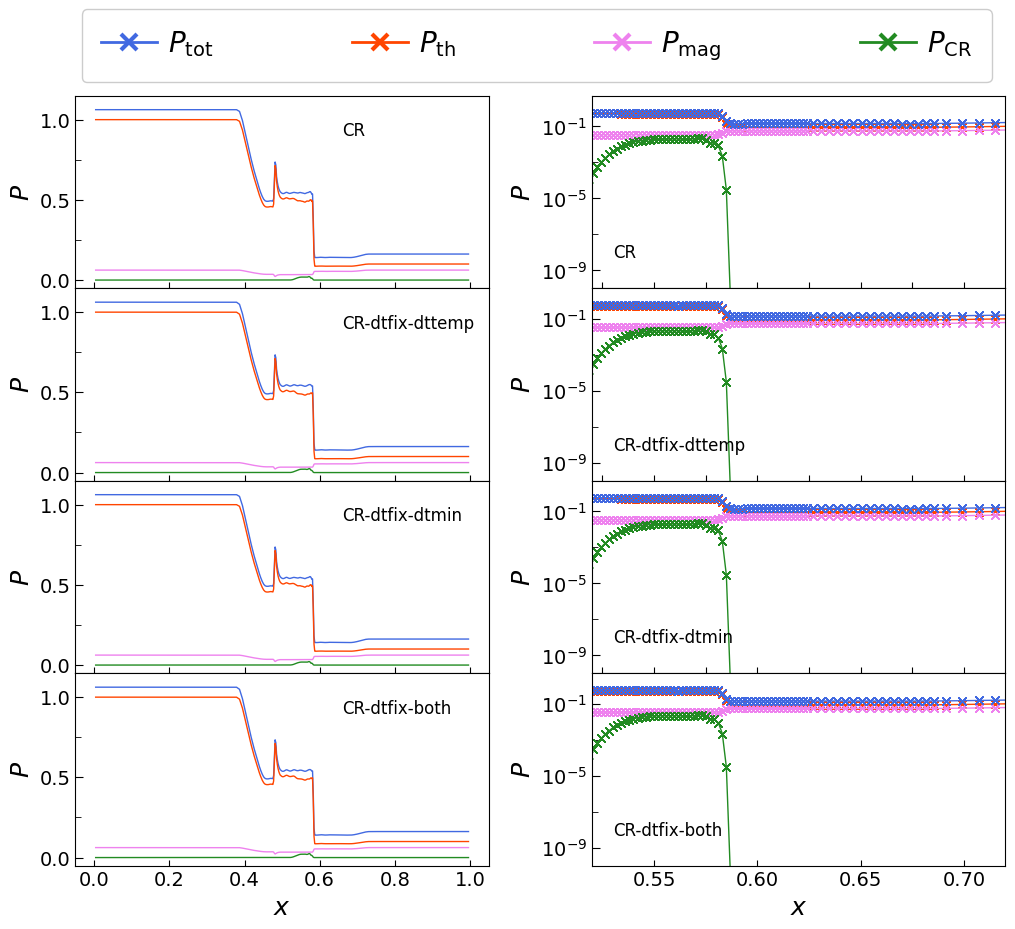

In [ ]:

fig = plt.figure(figsize=(12,10))
gs = fig.add_gridspec( len(sim_names), len(pres_ylims), hspace=0, wspace=0.25)
axs = gs.subplots(sharex=False, sharey=False)


for j in range(len(pres_ylims)):

    for i, sim_name in enumerate(sim_names):
    

        # plot CR and thermal components seperately
        ptot_arr, pth_arr, pmag_arr, pcr_arr = sim_pres_arr[i]

        axs[i,j].plot(sim_xcoords_arr[i][::region_filters[j]], ptot_arr[::region_filters[j]], ls="-", lw=1.0, color=pres_colors[0],zorder=1, rasterized=True)
    
        axs[i,j].plot(sim_xcoords_arr[i][::region_filters[j]], pth_arr[::region_filters[j]], ls="-", lw=1.0, color=pres_colors[1],zorder=1, rasterized=True)

        axs[i,j].plot(sim_xcoords_arr[i][::region_filters[j]], pmag_arr[::region_filters[j]], ls="-", lw=1.0, color=pres_colors[2],zorder=1, rasterized=True)

        if sim_name.find("CR") != -1:
            axs[i,j].plot(sim_xcoords_arr[i][::region_filters[j]], pcr_arr[::region_filters[j]], ls="-", lw=1.0, color=pres_colors[3],zorder=1, rasterized=True)

        if j == 1:
            axs[i,j].plot(sim_xcoords_arr[i][::region_filters[j]], ptot_arr[::region_filters[j]], ls="", lw=1.0, marker="x", color=pres_colors[0], ms=marker_sizes[j], label=r"$P_\mathrm{tot}$", zorder=1, rasterized=True)
            
            axs[i,j].plot(sim_xcoords_arr[i][::region_filters[j]], pth_arr[::region_filters[j]], ls="", lw=1.0,marker="x", color=pres_colors[1], ms=marker_sizes[j], label=r"$P_\mathrm{th}$", zorder=0, rasterized=True)

            axs[i,j].plot(sim_xcoords_arr[i][::region_filters[j]], pmag_arr[::region_filters[j]], ls="", lw=1.0,marker="x", color=pres_colors[2], ms=marker_sizes[j], label=r"$P_\mathrm{mag}$", zorder=0, rasterized=True)

            if sim_name.find("CR") != -1:
                axs[i,j].plot(sim_xcoords_arr[i][::region_filters[j]], pcr_arr[::region_filters[j]], ls="", lw=1.0,marker="x", color=pres_colors[3], ms=marker_sizes[j], label=r"$P_\mathrm{CR}$", rasterized=True)

        # limits
        axs[i,j].set_xlim(pres_xlims[j])
        axs[i,j].set_ylim(pres_ylims[j])

        if j == 0:
            axs[i,j].annotate(sim_labels[i], xy=(0.66, 0.9), fontsize=12)
        else:
            axs[i,j].annotate(sim_labels[i], xy=(0.53, 5e-9), fontsize=12)

        # external configurations
        # axs[i,j].label_outer()   # to ignore labels inside

        # x
        if i == len(sim_names) - 1:
            axs[i,j].set_xlabel("$x$", fontsize=18)
            axs[i,j].tick_params(axis='x', direction="in", which='major', size=4, labelsize=14)
            axs[i,j].tick_params(axis='x', direction="in", which='minor', size=2, labelsize=12)
        else:
            # axs[i,j].set_xlabel("", fontsize=18)
            axs[i,j].tick_params(axis='x', direction="in", which='major', size=4, labelsize=0)
            axs[i,j].tick_params(axis='x', direction="in", which='minor', size=2, labelsize=0)

        # y
        axs[i,j].set_ylabel(r"$P$", fontsize=18)

        if j == 0:
            axs[i,j].set_yticks([0.0, 0.5, 1.0], labels=[0.0, 0.5, 1.0])
            axs[i,j].set_yticks([0.25, 0.75], labels=[], minor=True)
            # axs[i,j].set_yticklabels([0.0, 0.25, 0.5, 0.75, 1.0], minor=True)
        elif j == 1:
            axs[i,j].set_yscale("log")
            axs[i,j].set_yticks([1e-9, 1e-5, 1e-1], labels=["$10^{-9}$", "$10^{-5}$", "$10^{-1}$"])
            axs[i,j].set_yticks([1e-7, 1e-3], labels=[], minor=True)

            # axs[i,j].yaxis.set_label_position("right")
            # axs[i,j].yaxis.tick_right()


        axs[i,j].tick_params(axis='y', direction="in", which='major', size=6, labelsize=14)
        axs[i,j].tick_params(axis='y', direction="in", which='minor', size=4, labelsize=12)

        
        
        
        

        # # scale
        # if j == 1:
        #     axs[i,j].set_yscale("log")

        # # ticks

        # # for x
        # if j == 1:
        #     axs[i,j].set_xticks([0.0, 0.25, 0.5, 0.75, 1.0])
        #     axs[i,j].set_xticklabels([0.0, 0.25, 0.5, 0.75, 1.0])
        #     axs[i,j].tick_params(axis='x', direction="in", which='major', size=8, labelsize=14)
        #     axs[i,j].tick_params(axis='x', direction="in", which='minor', size=6, labelsize=12)
        # else:
        #     axs[i,j].tick_params(axis='x', size = 0)
        #     axs[i,j].tick_params(axis='x', size = 0)

        # # for y
        # if i == 0:
        #     axs[i,j].tick_params(axis='y', direction="in", which='major', size=8, labelsize=14)
        #     axs[i,j].tick_params(axis='y', direction="in", which='minor', size=6, labelsize=12)
        # else:
        #     axs[i,j].tick_params(axis='y', size = 0)
        #     axs[i,j].tick_params(axis='y', size = 0)

        # if i == 1:
            #  axs[i,j].set_yticks()

# legend only for pres
# fig.legend(handles=pres_handles, bbox_to_anchor=(1.05, 0.33),ncols=1, fontsize=16 )
# fig.legend(handles=pres_handles, bbox_to_anchor=(1.05, 0.33), ncols=1, fontsize=18 , framealpha=1.0, columnspacing=3.0, borderpad=0.5, borderaxespad=0.4, labelspacing=1.0, handletextpad=0.3)

fig.legend(handles=pres_handles, bbox_to_anchor=(0.9, 0.98), ncols=4, fontsize=20, framealpha=1.0, columnspacing=5.0, borderpad=0.7, borderaxespad=0.5, labelspacing=0.5, handletextpad=0.4)

# fig.savefig(os.path.join("/home/watanabe/Projects/figures/briowu", "pres_plot.pdf"), dpi=300, bbox_inches="tight")

Plot other variables, but against each other as compared to next to each other

In [ ]:
# param_labels = [r"$\rho$",r"$v_x$",  r"$B_y$", r"$\mathcal{M}_1$"]
# param_limits = [
#     [(0, 1.1), (-0.4, 0.8), (-1.1, 1.1), (-0.5,4.5)],
#     [(0.09, 0.3), (-0.4, 0.8), (-1.1, -0.39), (-0.5,2.5)],
# ]

param_labels = [r"$\rho$",r"$v_x$",  r"$B_y$", "P"]
param_limits = [
    [(0, 1.1), (-0.4, 0.8), (-1.1, 1.1), (-0.05, 1.15)],
    [(0.09, 0.3), (-0.4, 0.8), (-1.1, -0.39), (0.01, 0.75)],
]

# param_colors = ["#023C40", "#D77A61", "#357DED", "#339E5A"]
sim_colors = ["k", "r", "b", "m"]
sim_markers = ["o", "^", "s", "d"]

# region_xlims = [(-0.05, 1.05), (0.64, 0.69)]
region_xlims = [(-0.05, 1.05), (0.575, 0.59)]

marker_sizes = [5.5, 7.0]

# create legend handles for pressure
sim_handles = [
    mlines.Line2D([0], [0],
                mec=sim_colors[0],
                mfc="none",
                marker=sim_markers[0],
                lw=1.0,
                color=sim_colors[0],
                markersize=10,
                alpha=0.8,
                label=sim_labels[0]),
    mlines.Line2D([0], [0],
                mec=sim_colors[1],
                mfc="none",
                marker=sim_markers[1],
                lw=1.0,
                color=sim_colors[1],
                markersize=10,
                alpha=0.8,
                label=sim_labels[1]),
    mlines.Line2D([0], [0],
                mec=sim_colors[2],
                mfc="none",
                marker=sim_markers[2],
                lw=1.0,
                color=sim_colors[2],
                markersize=10,
                alpha=0.8,
                label=sim_labels[2]),

    mlines.Line2D([0], [0],
                mec=sim_colors[3],
                mfc="none",
                color=sim_colors[3],
                marker=sim_markers[3],
                lw=1.0,
                markersize=10,
                alpha=0.8,
                label=sim_labels[3]),
]

region_filter = [150, 1]
region_mew = [0.5, 0.1]

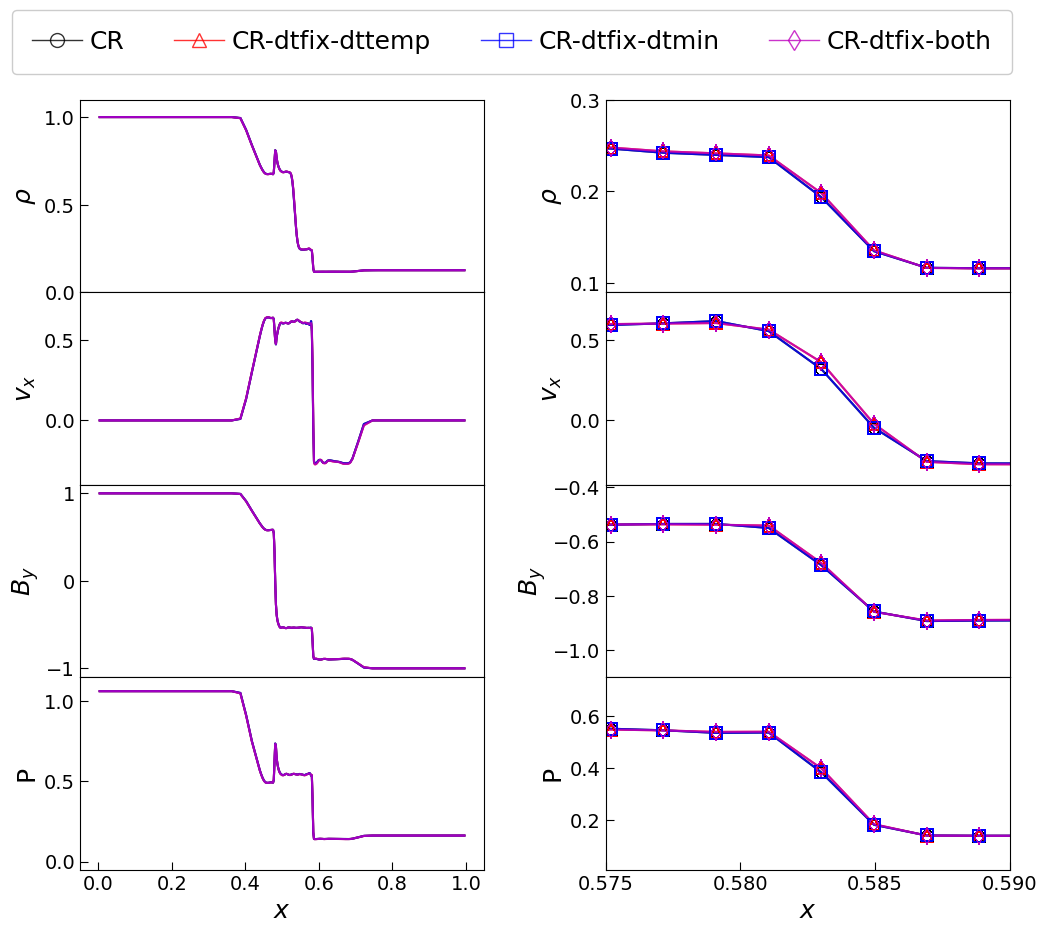

In [ ]:

fig = plt.figure(figsize=(12,10))
gs = fig.add_gridspec( len(params), len(region_xlims), hspace=0, wspace=0.3)
axs = gs.subplots(sharex=False, sharey=False)


for j in range(len(region_xlims)):

    for k in range(len(params)):
        
        for i in range(len(sim_names)):
            # axs[k,j].plot(sim_xcoords_arr[i][::region_filter[j]], sim_params_arr[i][k][::region_filter[j]], ls="", lw=0.1, marker=sim_markers[i], mfc="none", color=sim_colors[i], ms=marker_sizes[j], mew=region_mew[j], alpha=1.0, rasterized=True)
            axs[k,j].plot(sim_xcoords_arr[i][::region_filter[j]], sim_params_arr[i][k][::region_filter[j]], ls="-", lw=1.5, color=sim_colors[i], alpha=0.8, rasterized=True, zorder=0)
            if j == 1:
                axs[k,j].plot(sim_xcoords_arr[i][::region_filter[j]], sim_params_arr[i][k][::region_filter[j]], ls="", marker=sim_markers[i], mfc="none", color=sim_colors[i], ms=8.0, mew=region_mew[j], alpha=1.0, rasterized=True)

        # limits
        axs[k,j].set_xlim(region_xlims[j])
        axs[k,j].set_ylim(param_limits[j][k])

        # external configurations
        # axs[k,j].label_outer()   # to ignore labels inside

        # x
        if k == len(params) - 1:
            axs[k,j].set_xlabel("$x$", fontsize=18)
            axs[k,j].tick_params(axis='x', direction="in", which='major', size=6, labelsize=14)
            axs[k,j].tick_params(axis='x', direction="in", which='minor', size=4, labelsize=12)
        else:
            # axs[k,j].set_xlabel("", fontsize=18)
            axs[k,j].set_xticks([])
            axs[k,j].set_xticklabels([])

        axs[k,j].tick_params(axis='y', direction="in", which='major', size=6, labelsize=14)
        axs[k,j].tick_params(axis='y', direction="in", which='minor', size=4, labelsize=12)

        axs[k,j].set_ylabel(param_labels[k], fontsize=18)
        if j == 0:
            axs[k,j].tick_params(axis='y', direction="in", which='major', size=6, labelsize=14)
            axs[k,j].tick_params(axis='y', direction="in", which='minor', size=4, labelsize=12)
            # axs[k,j].set_yticklabels([0.0, 0.25, 0.5, 0.75, 1.0], minor=True)
        elif j == 1:
            axs[k,j].tick_params(axis='y', direction="in", which='major', size=6, labelsize=14)
            axs[k,j].tick_params(axis='y', direction="in", which='minor', size=4, labelsize=12)
        #     axs[k,j].set_yticks([])
        #     axs[k,j].set_yticklabels([])

            # axs[i,j].yaxis.set_label_position("right")
            # axs[i,j].yaxis.tick_right()


        # axs[i,j].tick_params(axis='y', direction="in", which='major', size=6, labelsize=14)
        # axs[i,j].tick_params(axis='y', direction="in", which='minor', size=4, labelsize=12)

# legend only for pres
# fig.legend(handles=pres_handles, bbox_to_anchor=(1.05, 0.33),ncols=1, fontsize=16 )
fig.legend(handles=sim_handles, bbox_to_anchor=(0.91, 0.98), ncols=4, fontsize=18 , framealpha=1.0, columnspacing=2.0, borderpad=0.8, borderaxespad=0.4, labelspacing=1.5, handletextpad=0.3)

# fig.savefig(os.path.join("/home/watanabe/Projects/figures/briowu", "param_plot.pdf"), dpi=300, bbox_inches="tight")

In [ ]:
# fig = plt.figure(figsize=(15,15))
# gs = fig.add_gridspec( len(params), len(sim_names), hspace=0, wspace=0)
# axs = gs.subplots(sharex=True, sharey=False)

# for i, sim_name in enumerate(sim_names):

#     for k, param in enumerate(params):

#         # plot numerical results
#         if param == "pres":

#             # plot CR and thermal components seperately
#             ptot_arr, pth_arr, pmag_arr, pcr_arr = sim_params_arr[i][k]

#             axs[k,i].plot(sim_xcoords_arr[i], ptot_arr, ls="", marker="o", color=pres_colors[0], ms=1.0, mew=1.0, label=r"$P_\mathrm{tot}$", zorder=1)
            
#             axs[k,i].plot(sim_xcoords_arr[i], pth_arr, ls="", marker="o", color=pres_colors[1], ms=1.0, mew=1.0, label=r"$P_\mathrm{th}$", zorder=0)

#             axs[k,i].plot(sim_xcoords_arr[i], pmag_arr, ls="", marker="o", color=pres_colors[2], ms=1.0, mew=1.0, label=r"$P_\mathrm{mag}$", zorder=0)

#             if sim_name.find("CR") != -1:
#                 axs[k,i].plot(sim_xcoords_arr[i], pcr_arr, ls="", marker="o", color=pres_colors[3], ms=1.0, mew=1.0, label=r"$P_\mathrm{CR}$")
#         else:
#             axs[k,i].plot(sim_xcoords_arr[i], sim_params_arr[i][k], ls="", marker="o", color=marker_color, ms=1.0, mew=1.0, alpha=0.9)

#         # labels
#         axs[k,i].set_xlabel("$x$", fontsize=18)
#         axs[k,i].set_ylabel(param_labels[k], fontsize=18)

#         # limits
#         axs[k,i].set_ylim(param_limits[k])

#         # ticks

#         # for x
#         if k == len(params) - 1:
#             axs[k,i].tick_params(axis='x', direction="in", which='major', size=8, labelsize=14)
#             axs[k,i].tick_params(axis='x', direction="in", which='minor', size=6, labelsize=12)
#         else:
#             axs[k,i].tick_params(axis='x', size = 0)
#             axs[k,i].tick_params(axis='x', size = 0)

#         # for y
#         if i == 0:
#             axs[k,i].tick_params(axis='y', direction="in", which='major', size=8, labelsize=14)
#             axs[k,i].tick_params(axis='y', direction="in", which='minor', size=6, labelsize=12)
#         else:
#             axs[k,i].tick_params(axis='y', size = 0)
#             axs[k,i].tick_params(axis='y', size = 0)

#         # legend only for pres
#         if param == "pres":
#             if sim_name.find("CR") != -1:
#                 axs[k,i].legend(handles=pres_handles, prop={"size":14}, loc="upper right")
#             else:
#                 axs[k,i].legend(handles=pres_handles[:3], prop={"size":14}, loc="upper right")

#         # if i == 1:
#             #  axs[k,i].set_yticks()

#         # external configurations
#         axs[k,i].label_outer()   # to ignore labels inside

# # fig.savefig(os.path.join("/home/watanabe/Projects/figures/sod_crinj", "CRinj_plot.pdf"), dpi=300, bbox_inches="tight")